In [2]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Load previously prepared dataset
df = pd.read_csv(
    "../data/daily_food_sales.csv",
    parse_dates=["date"]
)

df = df.sort_values("day_number").reset_index(drop=True)

# Recreate lag features
for lag in [1, 7, 14, 28]:
    df[f"lag_{lag}"] = df["units_sold"].shift(lag)

# Recreate rolling features
df["rolling_mean_7"] = df["units_sold"].shift(1).rolling(7).mean()
df["rolling_mean_28"] = df["units_sold"].shift(1).rolling(28).mean()

# Calendar features
df["day_of_week"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month

df = df.dropna(subset=[
    "lag_1", "lag_7", "lag_14", "lag_28",
    "rolling_mean_7", "rolling_mean_28"
])

# Load event information
calendar_events = pd.read_csv(
    "../data/raw/calendar.csv",
    usecols=["d", "event_name_1", "event_name_2"]
)

df_events = df.merge(
    calendar_events,
    on="d",
    how="left",
    validate="many_to_one"
)

df_events[["event_name_1", "event_name_2"]] = (
    df_events[["event_name_1", "event_name_2"]].fillna("No_Event")
)

# Define features
numeric_features = [
    "lag_1", "lag_7", "lag_14", "lag_28",
    "rolling_mean_7", "rolling_mean_28"
]

event_features = [
    "day_of_week", "month",
    "event_name_1", "event_name_2"
]

all_features = numeric_features + event_features

# Split data chronologically
train_events = df_events[
    df_events["day_number"] <= 1773
].copy()

validation_events = df_events[
    df_events["day_number"].between(1774, 1829)
].copy()

# Define preprocessing pipeline
event_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         event_features)
    ]
)

print("Preprocessing complete!")
print("Training rows:", len(train_events))
print("Validation rows:", len(validation_events))

Preprocessing complete!
Training rows: 1745
Validation rows: 56


In [3]:

from lightgbm import LGBMRegressor
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error
import numpy as np

# Build LightGBM using the same features as Ridge + Events
lgbm_model = Pipeline([
    ("preprocessor", clone(event_preprocessor)),
    ("model", LGBMRegressor(
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=15,
        min_child_samples=20,
        random_state=42,
        verbosity=-1
    ))
])

# Train using the same training period
lgbm_model.fit(
    train_events[all_features],
    train_events["units_sold"]
)

# Predict on the same validation period
lgbm_predictions = lgbm_model.predict(
    validation_events[all_features]
)

# Sales forecasts cannot be negative
lgbm_predictions = np.maximum(lgbm_predictions, 0)

# Calculate evaluation metrics
lgbm_mae = mean_absolute_error(
    validation_events["units_sold"],
    lgbm_predictions
)

lgbm_wape = (
    np.abs(
        validation_events["units_sold"].to_numpy()
        - lgbm_predictions
    ).sum()
    / validation_events["units_sold"].abs().sum()
) * 100

print(f"LightGBM MAE: {lgbm_mae:.2f}")
print(f"LightGBM WAPE: {lgbm_wape:.2f}%")


LightGBM MAE: 254.99
LightGBM WAPE: 9.74%


c:\Users\kyan\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\kyan\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\kyan\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\kyan\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^

           Model        MAE
  Ridge + Events 247.370000
        LightGBM 254.985991
Ridge Regression 258.770000
  Seasonal Naive 369.960000


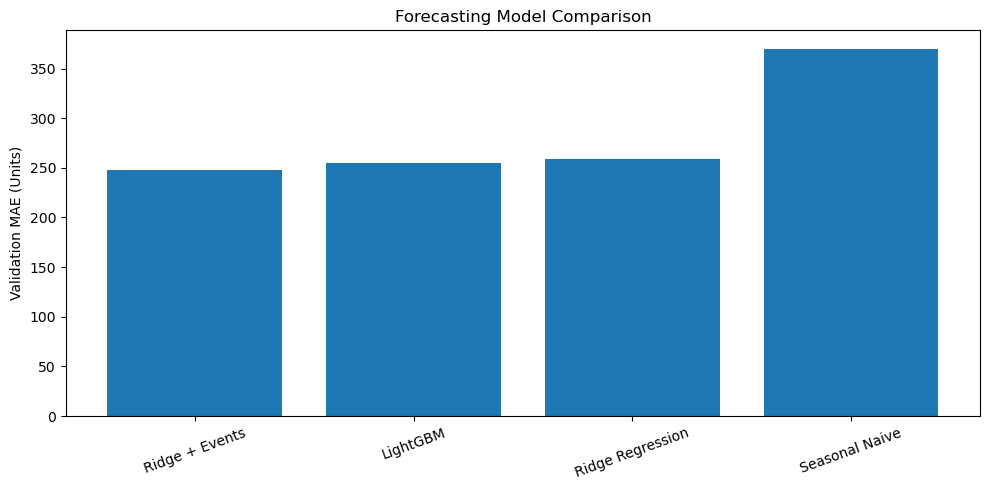

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Previously calculated validation results
naive_mae = 369.96
ridge_mae = 258.77
event_mae = 247.37

# lgbm_mae comes from your LightGBM training cell

results = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "Ridge Regression",
        "Ridge + Events",
        "LightGBM"
    ],
    "MAE": [
        naive_mae,
        ridge_mae,
        event_mae,
        lgbm_mae
    ]
})

results = results.sort_values("MAE")

print(results.to_string(index=False))

plt.figure(figsize=(10, 5))
plt.bar(results["Model"], results["MAE"])

plt.title("Forecasting Model Comparison")
plt.ylabel("Validation MAE (Units)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [7]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Recreate the Ridge + Events model
ridge_events = Pipeline([
    ("preprocessor", clone(event_preprocessor)),
    ("model", Ridge(alpha=10.0))
])

# Train using the same training period as LightGBM
ridge_events.fit(
    train_events[all_features],
    train_events["units_sold"]
)

# Generate predictions on the same validation period
event_predictions = ridge_events.predict(
    validation_events[all_features]
)

print("Ridge predictions generated successfully!")

Ridge predictions generated successfully!


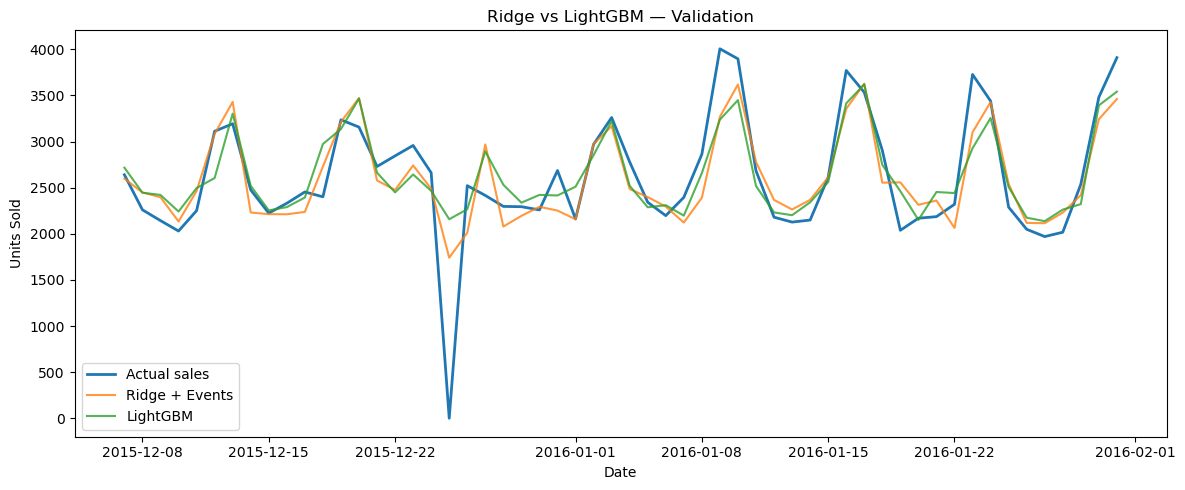

In [8]:

plt.figure(figsize=(12, 5))

plt.plot(
    validation_events["date"],
    validation_events["units_sold"],
    label="Actual sales",
    linewidth=2
)

plt.plot(
    validation_events["date"],
    event_predictions,
    label="Ridge + Events",
    alpha=0.8
)

plt.plot(
    validation_events["date"],
    lgbm_predictions,
    label="LightGBM",
    alpha=0.8
)

plt.title("Ridge vs LightGBM — Validation")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.tight_layout()
plt.show()
